# 08 - Permeability

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_a_foundations/08_permeability.ipynb)

**Part A - Petrophys Curriculum**

Porosity tells you how much fluid a rock can *store*; **permeability** ($k$) tells
you how fast that fluid can *flow*. It is what separates a tight, uneconomic zone
from a productive one, and unlike porosity it is not directly measured by any wire-
line tool - we always *estimate* it, either from log-based correlations or by
calibrating to core.

This lesson covers the two workhorse log-based estimators (**Timur** and
**Coates-Denoo**), how to flag impermeable zones, and - most importantly - how to
**calibrate a poro-perm transform to core data** and honestly report its
uncertainty.

NMR logs give a third route: Timur-Coates and SDR permeability from the
bound- and free-fluid volumes and the T2 distribution. 30/6-5 has no NMR log, so
that route is covered in **lesson 14 (NMR petrophysics)** on a real CMR log.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

By the end of this lesson you will be able to:

- Explain why permeability is estimated, not measured, from logs.
- Run the **Timur** and **Coates-Denoo** estimators with
  `pp.interpret(..., perm_method=...)` and understand their inputs (porosity and
  irreducible water saturation $S_{wirr}$).
- Check a log permeability against core plugs (`calibrate_permeability`) and tune
  an estimator's coefficient to them (`perm_coefficients`).
- Flag impermeable zones with `flag_impermeable`.
- Build a `CoreData` object and fit a poro-perm transform with
  `fit_poro_perm`, reading off $A$, $B$ and $R^2$.
- Plot $\log_{10}(k)$ vs porosity with the fitted line, overlay predicted vs core
  permeability, and reason about the scatter.

## Why this matters

Permeability spans **many orders of magnitude** for small changes in porosity, so
it is always worked in $\log_{10}$ space. The classic log-based estimators tie $k$
to two things the logs *can* give us:

- **Porosity** $\phi$ - more, better-connected pore space flows more easily.
- **Irreducible water saturation** $S_{wirr}$ - the water clinging to grain
  surfaces that never flows. High $S_{wirr}$ means fine grains, large surface area,
  and *low* permeability.

**Timur (1968):**
$$ k = a\,\frac{(100\,\phi)^{b}}{(100\,S_{wirr})^{c}} \qquad (a{=}0.136,\ b{=}4.4,\ c{=}2) $$

**Coates-Denoo:**
$$ k = 10000\,\phi^{4}\left(\frac{1-S_{wirr}}{S_{wirr}}\right)^{2} $$

Both are empirical and were tuned on particular rocks - which is exactly why we
end the lesson by calibrating to core.

### Prerequisites

Assumes the Part A lessons on porosity and water saturation (lesson 07).
`pp.interpret` computes the porosity, saturation and $S_{wirr}$ the estimators need,
so this lesson runs standalone.

In [2]:
import warnings
import pandas as pd
import petrophys as pp

pd.set_option("display.max_colwidth", None)   # show the trace's decisions in full
# The SWC/SOC unit note (lesson 02) repeats on every read of 30/6-5; hide it here.
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

## 1. Load the well; porosity and $S_{wirr}$

We again use **30/6-5** and its Brent Group reservoir (2841-2958 m;
`BRENT GP.` in the bundled tops), which carries laboratory core porosity (`PHIC`)
and core permeability (`KH_CORE`) - the ingredients we need for the calibration
section. We interpret it with the operator's saturation parameters of lessons 07
and 09: $R_w$ = 0.070 ohm.m at 230 degF, $a = 0.8$, $m = n = 2$.

The log-based estimators need an **irreducible** water saturation, not the total
$S_w$. Where $S_{wirr}$ really comes from, in order of preference: capillary
pressure measurements (lesson 15), NMR bound-fluid volume (lesson 14), and
only then a log-based quick-look. The workflow's quick-look is the classic
**constant-BVW (Buckles)** construction: in rock that is *at* irreducible
saturation, the bulk volume of water $BVW = \phi \cdot S_w$ is roughly constant
for a rock type, so

$$ S_{wirr} = \frac{BVW_{irr}}{\phi} $$

which correctly gives poor rock a higher $S_{wirr}$ than good rock (finer grains,
more surface area, more bound water). A single constant $S_{wirr}$ (setting
`swirr`) is the cruder alternative; it treats all rock alike, over-predicting
permeability in the poor rock. Either way there is a **validity condition**: the
$BVW_{irr}$ must come from rock that genuinely is at irreducible saturation. The
workflow takes it from hydrocarbon-bearing reservoir rock - the reservoir flag with
deep resistivity above 5 ohm.m - and writes $S_{wirr}$ as the curve `SWIRR_APP`.
The permeability step of the trace says what it did:

In [3]:
well = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"))
operator = dict(rw=0.07, rw_meas_temp="230 degF", a=0.8, m=2, n=2)
runs = {method: pp.interpret(well, **operator, perm_method=method) for method in ["timur", "coates"]}
runs["timur"].step("permeability").decisions

['RESFLAG, the net-reservoir flag from VCL, PHIE and SW, set before permeability (4611 samples)',
 'PHIE_CC and PERM_CC of the input removed: this run writes them only from a core model fitted to this well',
 'PHIE_CC of the core-correction step kept',
 'SWIRR_APP = BVWirr / PHIE (Buckles), BVWirr = median(PHIE x SW where resflag and RDEP > 5) = 0.0592 (n=216)',
 'Timur empirical permeability: k = 0.136 * (100 * PHIE)^4.4 / (100 * SWIRR)^2',
 'Permeability clipped to <= 10000 mD',
 'Empirical permeability curve stored as PERM (timur)',
 'Permeability: Timur',
 'Perm range: 0.000 - 10000.0 mD']

## 2. Log-based permeability: Timur and Coates-Denoo

`perm_method` selects the equation; both take porosity (`PHIE`) and `SWIRR_APP` as
fractions and return permeability `PERM` in **millidarcies (mD)**, clipped at
10,000 mD. Over the Brent Group:

In [4]:
pd.concat({method: r.statistics(["PERM"], top=2841, bottom=2958) for method, r in runs.items()}).round(2)

,,unit,samples,mean,p10,median,p90
timur,PERM,mD,636,65.64,0.07,22.26,223.29
coates,PERM,mD,636,74.27,0.00,21.73,259.46


Plot the two estimates on a shared log scale alongside porosity and $S_{wirr}$ (one
line per run, named by its key in `runs`). Where the curves diverge you are most
sensitive to which correlation you trust.

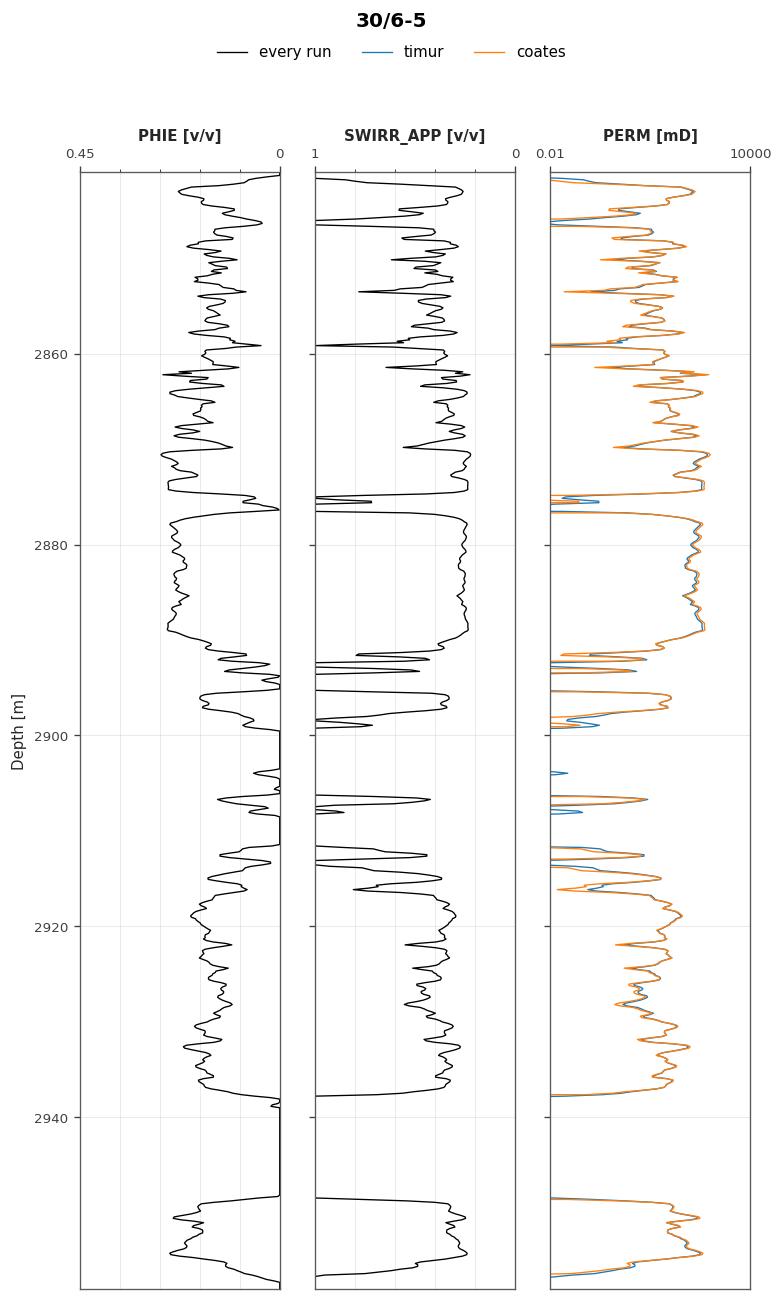

In [5]:
pp.plot(runs, curves=["PHIE", "SWIRR_APP", "PERM"], top=2841, bottom=2958)

#### Comparing empirical models

Both estimates follow porosity closely and fall to almost nothing where the
effective porosity does - in the shales, where the workflow removes the clay-bound
water. With the same porosity and $S_{wirr}$ the two equations give nearly the same
curve on this well, separating only in the tightest beds, although Timur and
Coates-Denoo were calibrated on different rock populations. Core calibration is
needed to decide whether either is right for this well.

`calibrate_permeability` compares a permeability curve with the core plugs at the
plug depths, in $\log_{10}$ space: `bias` is the mean of
$\log_{10}(k_{log}) - \log_{10}(k_{core})$ in decades, and `RMSE` the scatter.

In [6]:
from petrophys.interpretation.core_analysis import calibrate_permeability
from petrophys.interpretation.core_analysis.calibration import core_data

core = core_data(well)   # the plugs: PHIC porosity, KH_CORE permeability
{method: calibrate_permeability(r, core, log_curve="PERM") for method, r in runs.items()}

{'timur': CalibrationResult(Permeability (PERM, log10): n=170, R^2=0.480, bias=-0.8894, RMSE=1.5498, log = 0.879*core + -0.6968),
 'coates': CalibrationResult(Permeability (PERM, log10): n=150, R^2=0.532, bias=-0.6834, RMSE=1.1461, log = 0.682*core + -0.1090)}

Both estimators read low against the plugs: Timur by about 0.9 decade on average,
Coates-Denoo by about 0.7, with a scatter of more than a decade.

### The coefficients as an interpretation setting

In `pp.interpret` the coefficients are the `perm_coefficients` setting:
`{"a": ..., "b": ..., "c": ...}` sets the coefficient, porosity exponent and $S_{wirr}$
exponent of the equation the run uses - Timur $k = a\,(100\phi)^b/(100S_{wirr})^c$
(defaults 0.136, 4.4, 2), Coates-Denoo $k = a\,\phi^b\left((1-S_{wirr})/S_{wirr}\right)^c$
(10000, 4, 2) or Wyllie-Rose $k = a\,\phi^b/S_{wirr}^c$ (62500, 6, 2). Give only the ones you
change. In a LAS header they are `PERM_A`, `PERM_B` and `PERM_C`; a value passed to
`interpret` wins over the header.

A common local tune keeps Timur's exponents and recalibrates $a$ to core. Since $a$
scales $k$ at every sample, $a_{local} = 0.136 \times 10^{-\bar\Delta}$, where
$\bar\Delta$ is the bias above:

In [7]:
a_local = round(0.136 * 10 ** -calibrate_permeability(runs["timur"], core).bias, 3)
tuned = pp.interpret(well, **operator, perm_method="timur", perm_coefficients={"a": a_local})
a_local, calibrate_permeability(tuned, core)

(1.054,
 CalibrationResult(Permeability (PERM, log10): n=170, R^2=0.480, bias=-0.0001, RMSE=1.2692, log = 0.879*core + 0.1925))

The tuned $a$ (about 1.05 instead of 0.136) removes the average bias, but only part
of the scatter: the RMSE falls from 1.55 to 1.27 decades, so an individual plug can
still be a decade or more off. Name the method the
coefficients belong to: with `perm_method="auto"` this well gets its core model
where one is fitted and Coates-Denoo elsewhere, so a coefficient tuned for Timur
would be used as Coates-Denoo's $a$.

## 3. Flagging impermeable zones

Not every zone flows. `flag_impermeable(phi_s, phi_d, phi_n)` uses porosity-log
disagreement as a tell-tale: it flags a sample impermeable when the **sonic**
porosity greatly exceeds the **density** porosity ($\phi_S > 1.5\,\phi_D$ - the
signature of clay or undercompaction inflating the sonic slowness; note that a
vuggy rock shows the *opposite* pattern, because the sonic under-reads secondary
porosity), **or** when **neutron** porosity runs well above density
($\phi_N > \phi_D + 0.15$, the classic shale/clay-bound-water signature).

The workflow writes the three porosities as `PHIS`, `PHID` and `PHIN`; the share of
flagged Brent Group samples:

In [8]:
from petrophys.interpretation.permeability import flag_impermeable

brent_well = runs["timur"].well.depth_slice(2841, 2958)
flag_impermeable(brent_well["PHIS"].data, brent_well["PHID"].data, brent_well["PHIN"].data).mean().round(3)

np.float64(0.474)

#### Interpreting the impermeable flag

Almost half of the interval (47 %) is flagged: the shale, silt and coal beds of
the Ness Formation and the shaly beds within the Etive. The flag can be
used with the other reservoir criteria when defining net reservoir and net pay in
lesson 09.

## 4. Core calibration - the whole point

Log-based estimators are generic. The gold standard is to **fit the poro-perm
relationship to the field's own core plugs**. `fit_poro_perm(core)` takes
the `CoreData` object that `core_data` read from the well's `PHIC` and
`KH_CORE` curves and least-squares fits

$$ \log_{10}(k) = A\,\phi + B $$

returning a `PoroPermTransform` with `A`, `B`, `r_squared`, `n_points`, `rmse` and a
`.predict(porosity)` method.

In [9]:
from petrophys.interpretation.core_analysis import fit_poro_perm

transform = fit_poro_perm(core)
transform, transform.rmse

(PoroPermTransform(log10(K) = 21.72*PHI + (-2.54), R²=0.777, n=198),
 0.742241592975569)

### The core crossplot with the fitted line

The canonical QC plot: core $\log_{10}(k)$ on the y-axis against core porosity on
the x-axis, with the fitted transform overlaid. A tight cloud around the line means
a single porosity-permeability trend describes the rock; a fat cloud means other
controls (grain size, cementation, facies) matter and a single transform carries
real uncertainty.

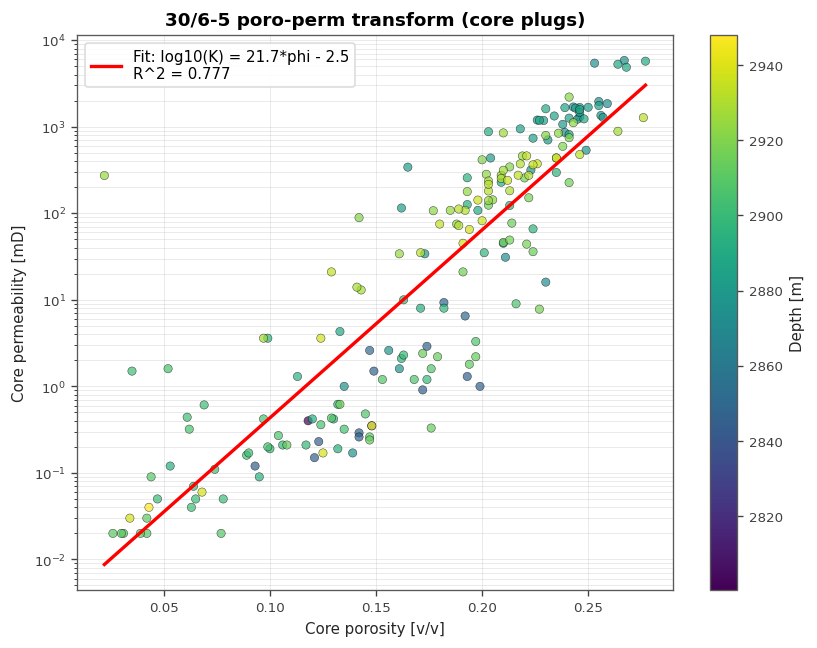

In [10]:
pp.crossplot(core, "PHIC", "KH_CORE", transform=transform, title="30/6-5 poro-perm transform (core plugs)")

### Predicted vs core permeability (unity plot)

Apply the transform back to the core porosities and cross-plot predicted against
measured permeability. Points on the 1:1 line are perfectly predicted; the vertical
scatter around it is the transform's intrinsic error. Because $k$ is log-normal,
we judge this in $\log_{10}$ space. `apply_poro_perm` writes the
predicted-permeability curve onto the well, `calibrate_permeability` compares it
with the core values, and `calibration_plot` draws the comparison.

CalibrationResult(Permeability (K_PRED, log10): n=198, R^2=0.777, bias=0.0000, RMSE=0.7422, log = 0.777*core + 0.2779)

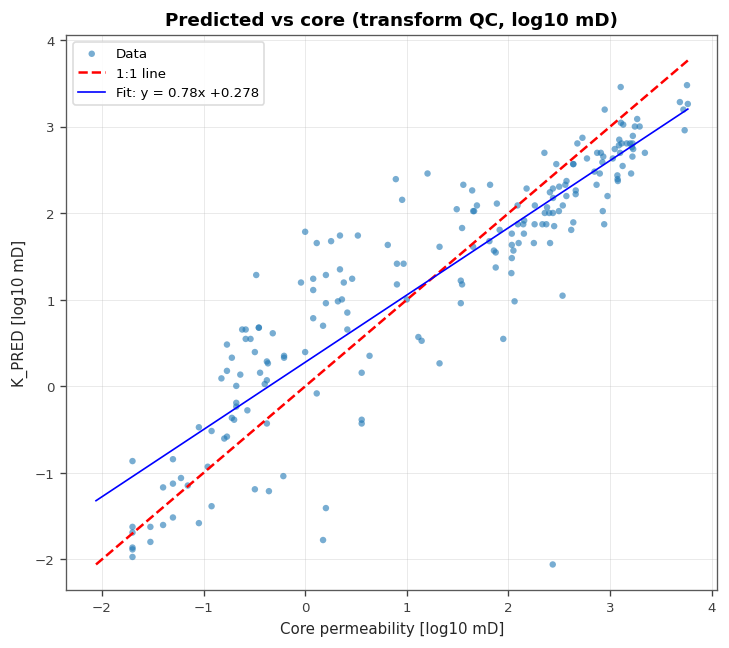

In [11]:
from petrophys.interpretation.core_analysis import apply_poro_perm

apply_poro_perm(well, transform, porosity_curve="PHIC", output_curve="K_PRED")
calibration = calibrate_permeability(well, core, log_curve="K_PRED")
pp.calibration_plot(calibration, title="Predicted vs core (transform QC, log10 mD)");
calibration

#### Calibration quality

The RMSE of about 0.74 in $\log_{10}$ is a typical error of a factor of about 5.5
($10^{0.74}$), wider than the factor-of-two to factor-of-three range expected from a
strong clastic calibration. Mixing several facies within one transform is a likely
source of the residual spread. Even so, it is well below the 1.15-1.55 decades of
scatter of the Timur and Coates-Denoo estimates of section 2.

`pp.interpret` fits the same kind of model itself, per formation where the plugs
allow, and writes it as `PERM_CC` from the core-corrected porosity (left undefined
above the net-rock clay cutoff and in rock shalier than the plugs). Checked against the plugs:

In [12]:
calibrate_permeability(pp.interpret(well, **operator), core, log_curve="PERM_CC")

CalibrationResult(Permeability (PERM_CC, log10): n=149, R^2=0.475, bias=0.0642, RMSE=0.9756, log = 0.551*core + 0.8639)

The workflow's core-calibrated permeability reads about 0.06 decade high on average,
with a scatter of about one decade: nearly unbiased, unlike the empirical
equations, but wider than the transform's own 0.74, because it is applied to log
porosity at the plug depths rather than to the plugs' own porosity.

## 5. A second core dataset - Costa (HW-3)

To show the workflow is general, we fit the Costa carbonate well **HW-3**, which
carries core-corrected porosity and permeability curves (`PHIE_CC`, `PERM_CC`).
These are continuous 0.5-ft log curves corrected to core, not plug measurements,
so on the HW-3 plot below "core" means core-corrected log values. Like every Costa
file, it covers only the Kharaib-2 reservoir interval. `core_data` reads
any curves you name as the core porosity and permeability.

In [13]:
hw3 = pp.read(pp.sample("HW-3"))
core_hw3 = core_data(hw3, porosity_curves=["PHIE_CC"], perm_curves=["PERM_CC"])
transform_hw3 = fit_poro_perm(core_hw3)
transform_hw3

PoroPermTransform(log10(K) = 5.74*PHI + (-0.50), R²=0.360, n=324)

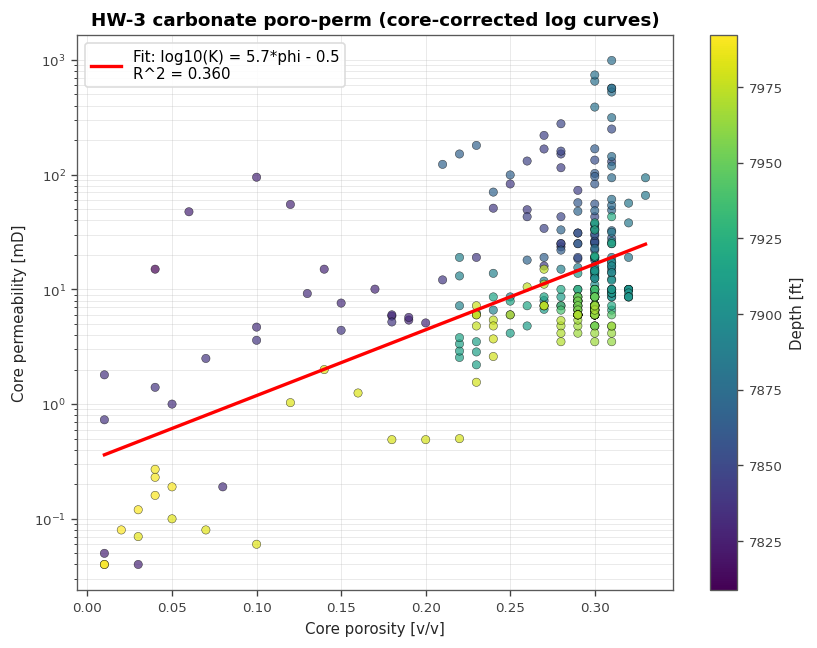

In [14]:
pp.crossplot(core_hw3, "PHIE_CC", "PERM_CC", transform=transform_hw3,
             title="HW-3 carbonate poro-perm (core-corrected log curves)")

### Interpreting the two trends

Neither cloud is tight. The **clastic** 30/6-5 plugs follow one trend over
several decades of permeability ($R^2$ 0.78, a slope of about 22 decades per unit
porosity), but the scatter around it is a factor of about 5.5, so facies and grain
size matter as well as porosity. The **carbonate** HW-3 cloud is looser still
($R^2$ 0.36) and much flatter (about 6 decades per unit porosity). Be careful what
it shows: these are core-corrected *log* curves sampled every 0.5 ft, not plugs,
and `PHIE_CC` is quantized (the vertical stripes in the plot). Part of the scatter
therefore comes from how the curves were built. Carbonate permeability is also
commonly controlled by pore *type* (intergranular vs vuggy vs fractured) as much as
by bulk porosity, which loosens such a cloud too, but this data set alone cannot
separate the two causes. The broader point of lesson 07 stands: a carbonate usually
needs more than a bulk-property law.

## Uncertainty - how much should you trust a permeability estimate?

Permeability is the least certain number in the evaluation. Sources of error:

- **The correlation is empirical.** Timur/Coates were tuned on specific rocks; off
  that rock type they can be off by an order of magnitude, as section 2 showed.
- **$S_{wirr}$ is itself estimated.** Since Timur has $S_{wirr}^{-2}$, a 20% error
  in $S_{wirr}$ moves $k$ by -31% (Swirr 20% too high) to +56% (20% too low).
- **Core-to-log scale mismatch.** A core plug is centimetres; a log sample averages
  decimetres. Vertical permeability, fractures and lamination are averaged
  differently.
- **The transform's own RMSE.** We reported it as a multiplicative factor - a "x2
  to x3" band is common and honest for a good clastic fit; this well's fit is wider
  (about x5.5), and carbonates are usually worse.

**Best practice:** report permeability as a *range* (e.g. P10/P50/P90 from the
transform residuals), always calibrate to core when core exists, and treat any
single deterministic $k$ curve with healthy suspicion.

## Pitfalls & parameter choices

- **Fractions in, mD out.** The estimators expect $\phi$ and $S_{wirr}$ as
  fractions (0-1); the workflow converts percent porosity logs when it reads them.
- **Use $S_{wirr}$, not $S_w$.** Feeding the full water saturation (which includes
  moveable water in transition zones) underestimates permeability.
- **Always work $k$ in $\log_{10}$.** Averaging permeability linearly is dominated
  by a few high values; the geometric mean (mean of $\log_{10}$) is the sensible
  central estimate.
- **A high transform $R^2$ is necessary but not sufficient** - check the unity plot
  for bias (points systematically above/below the 1:1 line).
- **Coefficients belong to an equation.** Set `perm_method` together with
  `perm_coefficients`.

## Recap

- Permeability is always **estimated**, never logged; work it in $\log_{10}$ space.
- **Timur** and **Coates-Denoo** (`perm_method="timur"`, `"coates"`) are the standard
  log-based estimators and need porosity and $S_{wirr}$, which the workflow builds
  with the Buckles constant-BVW construction.
- **`calibrate_permeability`** measures a permeability curve against core plugs;
  `perm_coefficients` tunes an estimator to them.
- **`flag_impermeable`** uses porosity-log disagreement to mark non-flowing streaks.
- **`fit_poro_perm(core)`** fits $\log_{10}(k)=A\phi+B$ to core plugs;
  read off $A$, $B$, $R^2$, RMSE and use `.predict()`.
- The clastic poro-perm trend is clear but carries a factor-of-five scatter; the
  carbonate cloud is looser, partly from pore type and, for HW-3, partly from
  quantized core-corrected log curves.
- Report permeability with an **uncertainty band**, not a single deterministic
  value.

## Try it yourself

> **Exercise 1.** Fit the 30/6-5 transform on the Etive Formation plugs only:
> `core_data(well, top=2865, bottom=2958)`. How much do $A$, $B$ and $R^2$
> move? What does that tell you about mixing formations in one transform?
>
> **Exercise 2.** Interpret with `perm_method="wyllie_rose"` and compare its bias
> against core with Timur and Coates-Denoo.
>
> **Exercise 3.** Interpret with a constant `swirr=0.15` instead of the Buckles
> $S_{wirr}$. How does the Timur permeability of the poor rock change?

## What's next

Continue with **09 - Reservoir Quality and Net Pay**, where permeability feeds into
flow-zone indicators (RQI/FZI), bulk-volume water, the three-stage net-pay flag,
and volumetrics (HCPV / OOIP / OGIP).